# Diagnostic Statistique de la Rigidité Textuelle
Ce notebook expérimente des métriques pour distinguer la **prose naturelle** de **textes très structurés**. L'objectif est de quantifier la "rigidité textuelle" d'un document à travers des indicateurs lexicaux, syntaxiques et statistiques.

Les indicateurs sont implémentés dans le package `text_rigidity` (dossier `text-rigidity/` à la racine du dépôt) : ce notebook les importe et les applique. Environnement : `uv sync --all-packages` à la racine du dépôt, puis le noyau Jupyter du `.venv` créé.


In [1]:
# Modèles officiels CCNet (Facebook AI) pour la perplexité : tokenizer SentencePiece et modèle de langue
# KenLM 5-grammes français (environ 2,6 Go), téléchargés au besoin dans models/
from text_rigidity import download_ccnet_models

SP_MODEL, LM_MODEL = download_ccnet_models("fr", dest="models")
PPL_MODELS = {"fr": (SP_MODEL, LM_MODEL)}
print("✅ CCNet models ready:", SP_MODEL, LM_MODEL)

✅ CCNet models ready: models/fr.sp.model models/fr.arpa.bin


In [2]:
import sentencepiece as spm
import unicodedata

sp = spm.SentencePieceProcessor()
sp.load(SP_MODEL)
text_test = "Est-ce que ce tokenizer découpe en mots, ou en subwords ?"
text_test = unicodedata.normalize("NFKC", text_test.lower().strip())
tokens = sp.encode_as_pieces(text_test)

" ".join(tokens)


'▁est - ce ▁que ▁ce ▁to ken izer ▁d é coupe ▁en ▁mots , ▁ou ▁en ▁sub word s ▁?'

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from text_rigidity import get_nlp

# Modèle spaCy pour les analyses de surface et POS (téléchargé au besoin)
nlp = get_nlp("fr")
print("Base dependencies and spaCy loaded.")

Base dependencies and spaCy loaded.


### I. Constitution du Corpus de Référence
Nous utilisons quatre types de documents pour calibrer nos métriques, allant de la fluidité extrême (Proust) à la structure rigide (Almanach du XVIIIe siècle).

In [4]:
corpus = [
    {
        "id": "1_Prose_Proust",
        "category": "Prose",
        "text": """Longtemps, je me suis couché de bonne heure. Parfois, à peine ma bougie éteinte, mes yeux se fermaient si vite que je n'avais pas le temps de me dire : « Je m'endors. » Et, une demi-heure après, la pensée qu'il était temps de chercher le sommeil m'éveillait ; je voulais poser le volume que je croyais avoir encore dans les mains et souffler ma lumière ; je n'avais pas cessé en dormant de faire des réflexions sur ce que je venais de lire, mais ces réflexions avaient pris un tour un peu particulier ; il me semblait que j'étais moi-même ce dont parlait l'ouvrage : une église, un quatuor, la rivalité de François Ier et de Charles Quint. Cette croyance survivait pendant quelques secondes à mon réveil ; elle ne choquait pas ma raison mais pesait comme des écailles sur mes yeux et les empêchait de se rendre compte que le bougeoir n'était plus allumé. Puis elle commençait à me devenir inintelligible, comme après la métempsycose les pensées d'une existence antérieure ; le sujet du livre se détachait de moi, j'étais libre de m'y appliquer ou non ; aussitôt je recouvrais la vue et j'étais bien étonné de trouver autour de moi une obscurité, douce et reposante pour mes yeux, mais peut-être plus encore pour mon esprit, à qui elle apparaissait comme une chose sans cause, incompréhensible, comme une chose vraiment obscure. Je me demandais quelle heure il pouvait être ; j'entendais le sifflement des trains qui, plus ou moins éloigné, comme le chant d'un oiseau dans une forêt, relevant les distances, me décrivait l'étendue de la campagne déserte où le voyageur se hâte vers la station prochaine ; et le petit chemin qu'il suit va être gravé dans son souvenir par l'excitation qu'il doit à des lieux nouveaux, à des actes inaccoutumés, à la causerie récente et aux adieux sous la lampe étrangère qui le suivent encore dans le silence de la nuit, à la douceur prochaine du retour.

J'appuyais tendrement mes joues contre les belles joues de l'oreiller qui, pleines et fraîches, sont comme les joues de notre enfance. Je frottais une allumette pour regarder ma montre. Bientôt minuit. C'est l'instant où le malade, qui a été obligé de partir en voyage et a dû coucher dans un hôtel inconnu, réveillé par une crise, se réjouit en apercevant sous la porte une raie de jour. Quel bonheur, c'est déjà le matin ! Dans un moment les domestiques seront levés, il pourra sonner, on viendra lui porter secours. L'espérance d'être soulagé lui donne du courage pour souffrir. Justement il a cru entendre des pas ; les pas se rapprochent, puis s'éloignent. Et la raie de jour qui était sous sa porte a disparu. C'est minuit ; on vient d'éteindre le gaz ; le dernier domestique est parti et il faudra rester toute la nuit à souffrir sans remède.

Je me rendormais, et parfois je n'avais plus que de courts réveils d'un instant, le temps d'entendre les craquements organiques des boiseries, d'ouvrir les yeux pour fixer le kaléidoscope de l'obscurité, de goûter grâce à une lueur momentanée de conscience le sommeil où étaient plongés les meubles, la chambre, le tout dont je n'étais qu'une petite partie et à l'insensibilité duquel je retournais vite m'unir. Ou bien en dormant j'avais rejoint sans effort un âge à jamais révolu de ma vie primitive, retrouvé telle de mes terreurs enfantines comme celle que mon grand-oncle me tirât par mes boucles et qu'avait dissipée le jour – date pour moi d'une ère nouvelle – où on les avait coupées. J'avais oublié cet événement pendant mon sommeil, j'en retrouvais le souvenir aussitôt que j'avais réussi à m'éveiller pour échapper aux mains de mon grand-oncle, mais par mesure de précaution j'entourais complètement ma tête de mon oreiller avant de retourner dans le monde des rêves.

Quelquefois, comme Ève naquit d'une côte d'Adam, une femme naissait pendant mon sommeil d'une fausse position de ma cuisse. Formée du plaisir que j'étais sur le point de goûter, je m'imaginais que c'était elle qui me l'offrait. Mon corps qui sentait dans le sien ma propre chaleur voulait s'y rejoindre, je m'éveillais. Le reste des humains m'apparaissait comme bien lointain auprès de cette femme que j'avais quittée il y avait quelques moments à peine ; ma joue était chaude encore de son baiser, mon corps courbaturé par le poids de sa taille. Si, comme il arrivait quelquefois, elle avait les traits d'une femme que j'avais connue dans la vie, j'allais me donner tout entier à ce but : la retrouver, comme ceux qui partent en voyage pour voir de leurs yeux une cité désirée et s'imaginent qu'on peut goûter dans une réalité le charme du songe. Peu à peu son souvenir s'évanouissait, j'avais oublié la fille de mon rêve.

Un homme qui dort, tient en cercle autour de lui le fil des heures, l'ordre des années et des mondes. Il les consulte d'instinct en s'éveillant et y lit en une seconde le point de la terre qu'il occupe, le temps qui s'est écoulé jusqu'à son réveil ; mais leurs rangs peuvent se mêler, se rompre. Que vers le matin après quelque insomnie, le sommeil le prenne en train de lire, dans une posture trop différente de celle où il dort habituellement, il suffit de son bras soulevé pour arrêter et faire reculer le soleil, et à la première minute de son réveil, il ne saura plus l'heure, il estimera qu'il vient à peine de se coucher. Que s'il s'assoupit dans une position encore plus déplacée et divergente, par exemple après dîner assis dans un fauteuil, alors le bouleversement sera complet dans les mondes désorbités, le fauteuil magique le fera voyager à toute vitesse dans le temps et dans l'espace, et au moment d'ouvrir les paupières, il se croira couché quelques mois plus tôt dans une autre contrée. Mais il suffisait que, dans mon lit même, mon sommeil fût profond et détendît entièrement mon esprit ; alors celui-ci lâchait le plan du lieu où je m'étais endormi, et quand je m'éveillais au milieu de la nuit, comme j'ignorais où je me trouvais, je ne savais même pas au premier instant qui j'étais ; j'avais seulement dans sa simplicité première, le sentiment de l'existence comme il peut frémir au fond d'un animal ; j'étais plus dénué que l'homme des cavernes ; mais alors le souvenir – non encore du lieu où j'étais, mais de quelques-uns de ceux que j'avais habités et où j'aurais pu être – venait à moi comme un secours d'en haut pour me tirer du néant d'où je n'aurais pu sortir tout seul ; je passais en une seconde par-dessus des siècles de civilisation, et l'image confusément entrevue de lampes à pétrole, puis de chemises à col rabattu, recomposaient peu à peu les traits originaux de mon moi."""
    },
    {
        "id": "2_Trade_Directory",
        "category": "Directory",
        "text": """# ALMANACH DU COMMERCE DE PARIS , POUR L'AN XIII.
## AGENS D'AFFAIRES.
ALLAIS , R. N. S. Augustin , 575.
Arnoux , R. S. Thomas du Louvre , 259.
Aubry , R. N. et Div. Lepelletier , 11.
Aufroy , R. de Choiseul , 9.
Bastide , R. du Cherche Midi , 295. — Lux.
Bernard , R. du Fb. Poissonnière , 147. —
Berthaume , R. du Mail , 378.
Beurgat , R. des Moulins , 494.
Béviere l'aîné , Pl. Vendôme , 112 et 25.
Béviere jeune , R. de la Monnoie , 31.
Blondel (Isidor) , R. Féroü , 992.
Bonjour , R. de la Concorde , 688. — Tuil.
Boulabert , R. S. Honoré , 43. — Tuil.
Bourgeois , R. Egalité , 18. — Lux.
Bournisien , R. S. Guillaume , 1141. — F. de Gren.
Boursier , R. de l'Université , 915.
Boyard , R. du Bacq , 1083 — F. de Gr.
Cabanne , R. et Div. du M. Blanc , 44.
Castellan , R. de Grammont , 553.
Chateauneuf , R. S. Dominique , 952. — F. de Gren.
Clement , R. Charlot , 40.
Combe , R. Montmartre , 115. — Mail.
Cosseron-Villenoisy , R. N. D. des Victoires , 19.
Courtin , R. Vivienne , 58. — Lepel.
Cristoffe frères , R. Quincampoix , 38.
Dainville , R. de Menars , 563.
Daoust , R. de Bondy , 47.
Daumergue , R. de Provence , 61.
Deal , R. du Fb. S. Honoré , 44. — Roule.
Delabretonnière , R. de la Loi , 755. — B. des Moul.
Delaunay , R. S. Dominique , 1055. — Gre.
Després , R. des Bourdonnais , 410. — G. F.
Demousseaux , R. de la Vrilliere , 6.
Derigny , R. J. J. Rousseau , 350.
Dubois , R. du Coq , 2. — Dr. de l'H.
Duroux , R. Projetée , 798.
Fricôt-Nerei , R. Geoffroy l'Asnier , 44.
Froment , R. et Div. du Mont Blanc , 68.
Gallemand , R. du Mail , 43.
Gavaudans , R. de Buffaut , 503.
Geneux , R. d'Anjou , 1370. — Roule.
Gennevey , R. S. Sauveur , 35.
Gillet , R. Mandar , 14.
Girardy (*avocat , directeur du bureau général de correspondance*) , R. Vivienne , 11. — Lepel.
Gosset , R. N. S. Eustache , 7.
Guillou , R. Montmartre , 263 , près celle de la Jussienne.
Hémery (*chargé d'affaires des manufactures de cristaux de S. Louis et Voneche*) , R. des Deux Ecus , 51.
Holchnit , R. de Grammont , 547.
Housset (*corresp. judic. , administrat. et toutes autres*) , R. de Seine , 1067. — Unité.
Hua (*bureau de garantie des créances hypothéc.*) , R. Cr. des P. Champs , 38.
Hue et Monsinglant , R. Mêlée , 29.
Issorat , R. et D. du F. Poissonnière , 2.
Jarry , R. des Foss. Montmartre , 27.
Lainé , R. des Quatre Fils , 27.
Laisné , R. de Cléry , 98. — Brutus.
Lavisse , R. Payenne , 498. — Indivis.
Lecomte , R. Montmartre , 158. — Brutus .
Legris , R. du Hasard , 12.
Lemoine (p. les effets perd.) , R. Mandar. — Contr. Soc.
Lemoine , R. du Cherche Midi , 274.
Lépine , R. N. Egalité , 335. — B. Nouv.
Lepy , R. N. S. Augustin , 29.
Louet (direct. des relat. civiles et littéraires) , R. N. D. de Recouvrance , 107.
Lyon , R. S. Honoré , 30. — H. au Bl.
Mailly , R. de la Madeleine , 1425. — Houle.
Martin-d'Anzay (bureau de garantie des créances hypothéc.) , R. Cr. des Petits Champs , 38. — H. au Bl.
Martinere , R. du Mont Blanc , 9.
Meslée , R. Vieille du Temple , 122. — H. Armé.
Monnet , R. Helvétius , 667. — Lepel.
Monnais , R. Chapon , 21. — Grav.
Montigny , R. du Bouloy , 56. — H. au B.
Musset jeune , R. du Mont Blanc , 14.
Paulet , R. du Fb. S. Honoré , 111. — Ch. Elysées.
Percheron , R. de Grenelle , 41. — Hal. au Bled.
Piat-Villeneuve , (cabinet de vente d'immeubles) R. Taitbout , 15.
Poirez , R. de l'Echelle , 560. — Tuil.
Pommarède , R. de Clichy , 36. — M. Bl.
Ragouleau jeune (propriét. et directeur du bureau de correspond. nation. et étrang.) , R. N. S. Augustin , 582.
Rey , R. S. Honoré , 80. — Tuil.
Richard , R. Hautefeuille , 14. — Th. Fr.
Richard (directeur de correspondance) , R. Montmartre , 106. — Mail.
Riquebour , R. Villedor , 715. — B. des M.
Riviere , R. du Mont Blanc , 48.
Romainville , R. Montmartre , 265. — C. S.
Roziers (G. C.) d'Orléans , R. des Orfév. , 7. — Mus.
Roux , R. N. S. Eustache , 25. — Brutus.
Sanné et comp. (bureau de correspond. générale) , R. du Gr. Chantier , 1. — H. Armé.
Sautry , R. N. S. Augustin , 26. — Lepel.
Savouret , R. Ste. Avoye , 37. — H. Arm.
Second , R. Projetée , 807. — Lepel.
Sevin (direct. du bureau de correspond.) , R. Ste. Avoye , 155. — Réunion.
Thariat , R. du Bacq , 630. — Ouest.
Thirouin , R. des Prouvaires , 325.
Thorin (Marc) , R. de l'Echiquier , 20. — Poissonn.
Tournal , R. du Faub. Poissonnière , 128.
Vandenarsse et Villemssens (direct. de l'administrat. centr. de correspond. nat. et étrangère) , R. Bétizy , 7. — Muséum.
Vidal , R. des Prouvaires , 30. — C. Soc.
Villain (pour les colonies) , R. S. Florentin , 668. — Tuil.
Villemmin , R. des Quatre Vents , 659. — Luxemb.
Waudin , R. des Fossés S. Germain des Prés , hôtel de la Foudrière.
Willaume-de-Séméries (direct. du bureau d'agence gén. de la médecine , sciences et arts) , Q. de l'Ecole , 12. — Mus.
## AGENS DE CHANGE DE PARIS.
AGÈZ , R. de la Vrillière , 6. — H. au B.
Archdeacon fils aîné , Boulevard de la Madeleine , 243. — Place Vend.
Beaumont , R. Basse du Rempart , 356. — Pl. Vend.
Bocher , R. Grange Batel. , 28. — M. Bl.
Boisson , boulev. Bonne Nouvelle , 16.
Boscary-Villeplaine (*syndic*) , R. Blanche , 2. — M. Blanc.
Boû , R. Bergère , 1012.
Boucarande , R. du Sentier , 19. — Brutus.
Bréant-Laneuville (*doyen*) , R. Ne. S. Eustache , 38. — Brutus.
Brésson , R. N. S. Eustache , 22. — Brut.
Caron jeune , R. Poissonnière , 177. — Brutus.
Carron , R. de la Concorde , 688. — Tuil.
Cheret , R. Helvétius , 21. — B. des M.
Chiboust , R. des Filles S. Thomas , 6. — Mail.
Coindre , R. de Provence , 19. — M. Bl.
Croizette-Desnoyers , R. N. d'Orléans , 7 et 268. — Nord.
Dartigue , R. de Grammont , 6. — Lep.
Delahaye , R. du M. Blanc , 384. — Pl. V."""
    },
    {
        "id": "3_Parliamentary_Debates_Page",
        "category": "Standardized",
        "text": """
**M. le rapporteur.** La commission accepte

le renvoi du contre-projet de M. le général Robert.

**M. le président.** Demandé par la commission, le renvoi est de droit.

Le contre-projet de M. le général Robert est donc renvoyé à la commission, ainsi que l'article 35 du projet de loi. (Adhésion.)

**M. le président.** La parole est à M. le ministre de la guerre.

#### DÉPÔT D'UN PROJET DE LOI

**M. de Freycinet, ministre de la guerre.** J'ai l'honneur de déposer sur le bureau du Sénat, au nom de M. le président du conseil, ministre du commerce, de l'industrie et des colonies, ainsi qu'au nom de M. le ministre des finances, un projet de loi, adopté par la Chambre des députés, tendant à allouer, sur l'exercice 1888, une subvention de 300,000 fr. à la colonie de la Guyane française, pour réparation des désastres causés par l'incendie de Cayenne, du 11 août 1888.

Je demande le renvoi à la commission des finances.

**M. le président.** Le projet de loi est renvoyé à la commission des finances.

Il sera imprimé et distribué.

#### DÉPÔT D'UN RAPPORT

**M. le président.** La parole est à M. Scheurer-Kestner.

**M. Scheurer-Kestner.** J'ai l'honneur de déposer sur le bureau du Sénat un rapport fait au nom de la commission chargée d'examiner un projet de loi, adopté par la Chambre des députés, tendant à rendre obligatoires la vérification et le poinçonnage par l'Etat des densimètres employés dans les fabriques de sucre pour contrôler la richesse de la betterave.

**M. le président.** Le rapport sera imprimé et distribué.

#### REPRISE DE LA DISCUSSION

**M. le président.** Nous arrivons, messieurs, à l'article 36.

J'en donne lecture :

« Art. 36. — Il est tenu par subdivision de région un registre matricule sur lequel sont portés tous les jeunes gens inscrits sur les listes de recrutement cantonal.

« Ce registre mentionne l'incorporation de chaque homme inscrit ou la position dans laquelle il est laissé et, successivement, tous les changements qui peuvent survenir dans sa situation jusqu'à sa libération définitive.

« Tout homme inscrit sur le registre matricule reçoit un livret individuel qu'il est tenu de représenter à toute réquisition des autorités militaire, judiciaire et civile.

« En cas d'appel à l'activité ou de convocation pour des manœuvres, exercices ou revues, la représentation du livret individuel doit avoir lieu dans les vingt-quatre heures de la réquisition.

« En tout autre cas, le délai est de huit jours. »

(L'article 36, mis aux votx, est adopté.)

**M. le président.** Nous abordons maintenant des articles sur lesquels des amendements sont présentés. Il conviendrait peut-être de suspendre la séance pendant un quart d'heure. (Assentiment.)

La séance est suspendue pendant un quart d'heure.

(La séance, suspendue à trois heures quarante-cinq minutes, est reprise à quatre heures dix minutes.)

**M. le président.** Nous arrivons à l'article 37, qui est conçu en ces termes :

« Art. 37. — Tout Français reconnu propre au service militaire fait partie successivement :

« De l'armée active pendant trois ans;\
« De la réserve de l'armée active pendant sept ans;

« De l'armée territoriale pendant six ans;\
« De la réserve de l'armée territoriale pendant neuf ans. »

Sur cet article, il y a trois amendements: l'un de M. Margaine, l'autre de M. Meina-dier, et le troisième de M. le général Billot.

La parole est à M. Margaine pour développer son amendement, dont je donne lecture :

« Tout Français reconnu propre au service militaire fait partie successivement :

« De l'armée active et de sa réserve pendant dix ans;

« De l'armée territoriale et de sa réserve pendant quinze ans. »

**M. Margaine.** Messieurs, l'amendement que j'ai déposé devant le Sénat combine dans un seul article trois dispositions qui sont sujettes à controverse : le service actif, la disponibilité, la réserve. L'amendement de M. le colonel Meina-dier, l'amendement de M. le général Billot, ma propre proposition dès le commencement de cette délibération sur le service du recrutement, font entrevoir au Sénat que la réduction du service à trois années a ému beaucoup d'esprits et qu'on voudrait retenir d'une main quelque chose de ce que l'on abandonne. Pour moi, je ne veux rien abandonner! (Approbation à droite.)

Je voudrais maintenir les dispositions arrêtant à cinq années le service prescrit par la loi actuelle, puisque je n'ai pas le droit et la possibilité de les élargir encore. (Nouvelle approbation sur les mêmes bancs.)

C'est donc là le but et la portée de mon amendement. Je parle, bien entendu, en mon nom personnel, et je ne suis pas, comme tout à l'heure, l'interprète de la commission. J'ai au contraire la commission contre moi. Je dois en faire la déclaration.

Messieurs, c'est le 18 mai 1876 qu'un député déposa sur le bureau de la Chambre un article de loi qui modifiait la loi de 1872, quelque chose d'identique à l'article de loi que l'on va discuter aujourd'hui.

Il y a juste treize ans que cette discussion est soulevée devant le pays, devant le Parlement; nous sommes au 21 mai 1889; la solution n'est pas encore intervenue.

Eh bien, je m'adresse aux adversaires de la loi comme à ses partisans. Aux partisans de loi je dis : Treize années se sont écoulées depuis l'époque où la question a été posée, et vous qui voulez cette modification, vous, administrateurs de l'armée qui la croyez bonne, est-ce que vous n'avez pas souffert de voir que le seul obstacle à l'introduction en fait de cette disposition dans l'armée était la loi elle-même? l'obstacle! c'était le Parlement qui devait intervenir pour modifier la loi. Alors, ne pensez-vous pas que si l'on avait laissé au pouvoir exécutif le soin de prendre, sous sa responsabilité, les dispositions conformes à cette conviction qui vous eût animés pendant ces treize années, vous devriez m'approuver de prévoir pour l'avenir la possibilité de ne pas laisser passer treize années pendant lesquelles les Parlements, poussés par des sentiments que je ne veux pas apprécier, que je n'ai pas à définir, peut-être très louables, mais peut-être aussi étrangers aux véritables intérêts de l'armée, laisser passer, dis-je, treize années sans pouvoir appliquer des dispositions que vous croyez bonnes?

Mais si je me place au point de vue de ma propre opinion à moi, si je calcule que ces dispositions nouvelles sont chose désastreuse; que petit à petit l'introduction dans la législation de cette mesure va infiltrer dans notre constitution militaire quelque chose de fatal, comme j'en ai la conviction, pourquoi n'admettriez-vous pas que je puisse entrevoir la difficulté où l'on"""
    },
    {
        "id": "4_Civil_Record",
        "category": "Standardized",
        "text": """1755, 1 octobre, AN, Z1j 824B

Visite et estimation des biens immeubles dépendant des successions de défunts sieur François Monroy et Claude Varenne, son épouse.

À M. Jérôme d'Argouges, lieutenant civil.

À la requête du sieur Philippe Deschamps, marchand orfèvre à Paris, au nom et comme tuteur ad hoc de demoiselle Françoise-Thérèse Monroy et de André-Charles Monroy, enfants mineurs de défunt Charles Monroy, marchand plâtrier à la Courtille, et Thérèse-Geneviève Guernet, son épouse, à présent sa veuve ; sur 1 arpent de terre en une pièce sise sur le terroir de Romainville, lieu-dit les Fontaines ;

retirés en la maison de Étienne Couteux, jardinier, locataire de ladite pièce de terre.

Sentence de vous, Monsieur, rendue au Parc civil du Châtelet le 12 mars dernier entre ledit sieur Philippe Deschamps, ayant lesdits mineurs renoncé à la succession de leur père (greffe de M. Troussard, 30 juillet dernier), lesdits mineurs, par représentation de leur père, héritiers conjointement pour un quart de défunt François Monroy, leur aïeul paternel, et pour un pareil quart de demoiselle Claude Varenne, leur aïeule, ledit Deschamps élu à ladite charge par sentence de vous, Monsieur, du 14 janvier dernier, homologative de l'avis des parents et amis, demandeur en intervention suivant sa requête verbale du 30 janvier dernier, tendant entre autres choses afin d'entérinement des lettres de rescision par eux audit nom obtenues le 29 dudit mois de janvier ; Jean Colas, marchand de fer à Paris, et demoiselle Denise Monroy, sa femme, elle héritière pour un quart dudit défunt François Monroy et Claude Varenne, sa femme ; Jean Pillon, marchand mercier à Paris, et Marie-Claude Monroy, sa femme, elle héritière pour un quart dudit défunt François Monroy et Claude Varenne, sa femme ; Marie-Jeanne Drancy, tant comme veuve de défunt Jean-François Monroy que comme tutrice aux personnes et biens de Marie-Jeanne Monroy et Jacques Monroy ; Gabriel Monroy, majeur, Étienne Leclerc, marchand fripier, et Nicole Monroy, sa femme, Pierre Trancard, aussi marchand fripier, et Marie-Claude Monroy, sa femme, lesdits Marie-Jeanne Monroy, Jacques-Henri Monroy, mineurs, Gabriel Monroy, Nicole Monroy et Marie-Claude Monroy héritiers chacun pour un cinquième dudit défunt Jean-François Monroy, leur père, lequel était héritier pour un quart.

Thérèse Guernet, veuve de Charles Monroy, marchand plâtrier à Paris, d'avec lequel, en son vivant, elle était séparée quant aux biens, créancière de sa succession, ayant renoncé pour lesdits Françoise-Thérèse et André-Charles Monroy à la succession ; Jean-Louis Troussard, bourgeois de Paris, au nom et comme curateur créé par sentence du 1er août aussi dernier à la succession vacante dudit défunt Charles Monroy ;

par laquelle sentence vous avez, Monsieur, reçu ledit Philippe Deschamps audit nom partie intervenante, et avez les lettres de rescision entérinées, en conséquence avez remis lesdits mineurs Charles Monroy en tel et semblable état qu'ils étaient avant les partages provisionnels et définitifs des 17 décembre 1751 et 17 septembre 1753, et, avant de faire droit sur la demande en nullité desdits partages formée par ledit Deschamps, avez ordonné que, à la requête dudit sieur Deschamps, les immeubles dépendants des successions desdits défunts François Monroy et Claude Varenne seraient prisés et estimés par experts.

Autre sentence de vous, Monsieur, rendue au Parc civil dudit Châtelet le 6 septembre dernier entre les mêmes parties ; inventaire après le décès de demoiselle Claude Varenne (Gouvion et son confrère, 18 août 1738) ; inventaire après le décès de François Monroy (Boursier et son confrère, 17 mai 1751) ;

transportés en ladite (sic) maison grande rue du faubourg-du-Temple à la Basse-Courtille. Nous avons proceeded au relevé des immeubles réels dépendant de la succession (descriptif détaillé). Ladite maison, cour, jardin ou marais en dépendant, tient d'un côté à droite à M. Drancy, d'autre côté à gauche audit sieur Drancy, par-derrière au nommé Renon, jardinier, et par-devant sur ladite grande rue du faubourg-du-Temple ou Basse-Courtille. Lesdits défunts sieur et dame Monroy n'ont acquis que le terrain sur lequel ils ont fait construire ladite maison, contenant 65 perches ou environ, faisant partie de 7 quartiers de terre par eux acquis de Philippe Godefroy, maçon, par contrat (Aveline, 26 janvier 1697) ; sur les 110 perches de surplus ils ont fait pareillement construire une autre maison qu'ils ont délaissée à titre de rente foncière à Pierre Damour. Ayant fait attention à la situation, distribution et construction des bâtiments de ladite maison, à leur âge, à ce qu'ils ne sont occupés que par des gens du peuple, ce qui peut opérer souvent des non-valeurs, et enfin aux réparations dont elle est susceptible, et eu égard au cours du temps présent, nous estimons ladite maison, cour et jardin ou marais, circonstances et dépendances, valoir ensemble la somme de 19 500 livres.

Transportés au village de Belleville en une maison sise grande rue dudit lieu, tenue et occupée par le nommé Bordier, vigneron (long descriptif) ; ladite maison, jardin et clos au-derrière et dépendances tiennent d'un côté à droite à M. le marquis de Soupire, à gauche dans la partie vers la rue à Jean-Baptiste Oyon, ensuite à Jean-Baptiste Boudin, et vers le bout au droit du clos au sentier qui sépare Pierre Vitry d'avec ledit clos par-derrière, aboutissant au sentier qui conduit derrière l'église et par-devant sur ladite grande rue dudit lieu de Belleville. Ont été acquis par ledit défunt sieur François Monroy, depuis le décès de ladite demoiselle Claude Varenne, sa femme, de Jacques Monroy, vigneron, et Catherine-Françoise Savart, sa femme, Étienne Malessart, jardinier, et Marie-Marguerite Boucault, sa femme, par trois contrats : 1. (Rouveau, 2 octobre 1744), et les deux autres (Quentin, 25 octobre 1746 et 9 février 1747). Estimé 4 600 livres.

Le 9 décembre, transportés à la butte de Chaumont ; un emplacement ou pièce de terre sur lequel est un moulin à vent, avec son pied de maçonnerie et carcasse de moulin en planches, avec ses tournants et travaillants. À peu de distance dudit moulin est situé un petit corps de bâtiment pour le logement du meunier ;

sous lequel emplacement est une carrière dans laquelle nous descendrons dans notre prochaine vacation, pour connaître autant comme il sera possible la quantité de matière qui reste à fouiller, afin d'en porter une appréciation plus juste.

Nous avons reconnu que ledit emplacement contient environ 5 quartiers, tenant d'un côté à Robert Drancy, d'autre côté aux héritiers Drancy, d'un bout aux héritiers Jourdain, et d'autre à [blanc].

Acquisition qu'ils en ont faite, conjointement, de Sébastien Langlois, maître menuisier à Paris, et Marie-Geneviève Gaultier, sa femme par contrat (Masson, 22 février 1736), moyennant la somme de 20 500 livres. Attendu que nous sommes arrivés tard à cause de la difficulté du mauvais chemin dans la saison où nous sommes pour monter à ladite butte de Chaumont.

Entrés dans la carrière sous les cinq quartiers de terre dont il s'agit. La plus grande partie desdits 5 quartiers de terre est fouillée, en sorte qu'il n'en reste qu'environ un tiers en place qui ne l'est pas, ce qui est une considération essentielle qui doit déterminer notre estimation, d'autant mieux qu'il peut arriver, comme nous le pensons, que le moulin qui est sur ladite carrière soit en porte à faux, ce qui donnerait lieu, si ledit moulin de trouvait sans fondement, à une chute et destruction d'icelui. Le tout estimé 6 800 livres.

Transportés sur une pièce, tant carrière fouillée que terres en friche, contenant 7 arpents 1 quartier ou environ, sise près Paris à ladite butte de Chaumont, dont un sixième non divis appartient et fait partie des biens des successions desdits défunts sieur et dame Monroy. Ladite pièce de terre tient d'un côté aux héritages par nous estimés en notre vacation du 9 du présent mois, de relevée, d'autre côté au nommé Rousseau, par un bout au chemin de Pantin. Ledit sixième non divis fait partie des conquêts de communauté au moyen de l'acquisition qui en a été faite de Jeanne-Catherine Jourdain, veuve en dernières noces de Antoine Dubuisson, compagnon cartier à Paris, par contrat (Besnier, 20 juin 1724), moyennant la somme de 1 500 livres.

Lesdites terres sont absolument en friche et ne produisent aucun rapport ; ledit sixième ne sert pour ainsi dire qu'à l'exploitation de la carrière ci-dessus ; il en coûterait beaucoup pour mettre en valeur ladite pièce de terre, ce qui nous fait considérer cet objet comme un bien imaginaire, d'autant mieux que la dépense qu'il faudrait faire pour en tirer du produit coûterait autant que le fonds de ladite pièce de terre, ce que nous rapportons pour mémoire.

Nous nous sommes ensuite transportés sur une carrière à plâtre fouillée et terres en dépendant, sise au bas et près ladite butte de Chaumont, de laquelle carrière et terres il ne nous a été communiqué aucun titre de propriété par les parties, et n'ont point non plus été inventoriés dans les inventaires des deux défunts, ce qui nous met hors d'état et dans l'impossibilité de pouvoir distinguer au juste la nature de cet objet. Nous observons simplement que cette carrière et terres font partie de l'article 5 de la masse du partage des biens et successions desdits défunts laissés en commun entre les parties, et que, par l'énoncé qui en a été fait audit article, il paraît que cette carrière et terres ont été délaissées et abandonnées audit défunt sieur François Monroy par Pierre Pasquier du But par contrat (Cleret, 9 septembre 1712). Ils tiennent des deux côtés aux héritages ci-dessus, et d'un bout audit chemin de Pantin.

Lesquelles carrière et terres sont dans le même cas de celle ci-dessus, entièrement en friche, et qui ne sert que de passage pour l'exploitation de la carrière dont nous avons parlé, et sur lesquelles carrière et terres il y a actuellement des fours à plâtre. Nous regardons donc cet objet comme un bien imaginaire, puisqu'il n'a aucun produit, et que, pour qu'il en ait, il faudrait dépenser pour les mettre en valeur autant et peut-être plus que lesdites carrières ne valent. Il conviendrait de les réunir, ainsi que le sixième de la pièce ci-dessus, à la propriété des 5 quartiers de terre en carrière que l'on exploite actuellement, sur laquelle est le moulin dont nous avons parlé. Cette réunion convient d'autant mieux que lesdites terres et friche servent de passage et à exploiter ladite carrière, et qu'elles y tiennent immédiatement, ce que nous rapportons pour mémoire seulement.

Transportés sur une pièce, tant vignes que terres labourables, sise au terroir de Belleville. Elle consiste :

1° en 1 quartier et demi, lieu-dit le Petit-Pressoir, tenant d'un côté à Simon Robineau, d'autre à Ambroise Richer, d'un bout à Jean-Baptiste Boudin, et par bas à Claude Boudin ;

2° en 6 perches de vignes audit terroir de Belleville, tenant d'un côté à Pierre Milcent, d'autre à [blanc], par bas à Denis Chaillou, et par haut à Jean-Baptiste Faucheur ;

3° en 9 perches, tant vignes que perches, audit terroir, lieu-dit le Grand Arpent, tenant d'un côté à Nicolas-Noël Lambert, d'autre à Jean Savart, par haut à la sente qui conduit du Ménilmontant à Belleville ;

4° en 1 demi-arpent de terre, lieu-dit les Sonneries, tenant d'un côté à Blaise Boudin, d'autre à François Faucheur, par haut à Jacques Hallé, et par bas à une sente ;

et enfin, en 5 perches de terres sises lieu-dit les Mignottes, tenant d'un côté audit Nicolas-Noël Lambert, d'autre à [blanc], par haut aux terres de la dame Verblé, et par bas à [blanc].

Lesdites 5 pièces contiennent ensemble 1 arpent 8 perches, et font partie d'1 arpent 16 perches et demie que lesdits défunts ont acquis de Jeanne Bordier, veuve de Louis Chaudron, vigneron, par contrat (Aveline, 16 novembre 1704), moyennant la somme de 700 livres ; les 8 perches de surplus, lesdits sieur et demoiselle Monroy les ont vendues depuis ladite acquisition. Estimé 924 livres.

Transportés sur plusieurs pièces d'héritage,

la première contenant 1 demi-quartier de terre labourable, située sur le terroir de La Villette, lieu-dit les Bas Barreaux, tenant d'une part à la veuve Denis Cottin, d'autre à Geneviève Couteux, par haut aux nommés Leblanc et par bas à la dame Demoncrif ;

la seconde, de pareil demi-quartier, planté en groseilliers, sise au même terroir de La Villette, lieu-dit Bas-Ballettes, tenant d'un côté à ladite Geneviève Couteux, d'autre à Ambroise Cottin, d'un bout à Blaise Boudin, et d'autre au nommé Loiseau ;

la troisième, de 10 perches de terre située aux terroirs de Pantin et du Pré-Saint-Gervais, lieu-dit le Clos Baril, tenant d'une part à Jean Couteux, d'autre à un fossé, aboutissant d'un bout à Jacques Osmont, et d'autre bout sur le grand chemin conduisant de Belleville à Romainville ;

et la quatrième contenant 4 perches, sise sur le terroir de Belleville, lieu-dit les Envierges, sur laquelle est un noyer ; tenant d'une part aux héritiers et représentants dudit Jean-Baptiste Monroy, d'autre à Claude Boudin, par haut au nommé Rousseau et par bas sur la sente. Lesdites quatre pièces contenant ensemble 39 perches.

Acquisition qu'il en a faite depuis le décès de sa femme, de Joseph Couteux, menuisier à Paris, et Marie-Geneviève Mollier, sa femme, par contrat (Rouveau, 28 février 1751).

Estimé 264 livres.

Transportés à Bagnolet ; pièces sises sur les terroirs de Bagnolet et Charonne :

1° 4 perches, Bagnolet, Blancheny, Henri Souchet, héritiers et représentants Jacques Hébert ;

2° Bagnolet, Montamy ou Caillesse, Nicolas Simon, veuve Jean Maurice ;

3° 3 perches, même terroir, Faucillon, héritiers de la veuve Alexandre Prudhomme, Jacques Souchet ;

4° 6 perches, Bagnolet, Vauchary, Pierre Graindorge, héritiers Souchet ;

5° 8 perches, Bagnolet, le Clos Breton, Philippe Lenain, sentier ;

6° 6 perches de terre, Charonne, Serveine, Mgr le duc d'Orléans, héritiers de Étienne Renard ;

7° 3 perches de terre, Charonne, Montibeuf, héritiers et représentants la veuve Claude Savart, sieur Porlier.

Lesdites sept pièces contenant ensemble 36 perches, tant terres labourables, vignes que groseilliers, louées actuellement à Toussaint Graindorge, et font partie d'autres terres et héritages acquis de Jean Nezot, maître boulanger à Paris, et Geneviève Varenne, sa femme, Jean Poyer, marchand de vin, et Barbe Varenne, sa femme, par deux contrats (Aveline, 1er mai 1709 et 15 septembre 1710). Les ventes avaient mesuré 166 perches ; il reste 130 perches que nous n'avons point trouvées, et qui font un vide. Estimé 462 livres.

Transportés sur le terroir de Charonne :

1° 6 perches, Gâtines, François Paul, Ambroise Cottin (etc.)

… 7° et 8° (30 perches et demie) Boursier, 20 décembre 1727 : 300 livres ; et les six pièces de surplus (55 perches), 990 livres ; etc. Charonne (1 020 livres) ; Saint-Laurent lez Paris, lieu-dit la Fontaine-au-Roi ou la Haute-Borne, 1 quartier ou environ planté tant en pieds de raisin, verjus, amandiers, abricotiers qu'autres arbres à haute tige avec deux puits en icelui ; contrat Boursier, 19 février 1729.

Transportés sur une pièce de terre contenant 1 arpent ou environ, faisant plusieurs angles, sous partie de laquelle était ci-devant une carrière, située au terroir de Pantin du Pré-Saint-Gervais, lieu-dit le Plantin : acquisition Rouveau, 21 mars 1720 (2 200 livres). Estimé 792 livres. La pièce de Romainville : 660 livres.

Les parties n'ont pas communiqué tous les titres documentant la propriété des parcelles.

Maison sise à Paris, rue Saintonge : acquise par François Monroy de demoiselle Madeleine Tasché, veuve du sieur Louis Lamesson, maître maçon, entrepreneur de bâtiments à Paris (Boursier, 27 octobre 1744) (3 700 livres) : estimée 4 600 livres.

Addition des immeubles acquis en communauté : 29 178 livres ; acquêts du seul François Monroy : 9 464 livres ; immeubles qui peuvent être propres : 990 livres ; autres immeubles dont l'espèce nous est absolument inconnue, n'ayant point eu de titres : 1 680 livres.

Total de tous les immeubles ci-dessus : 41 312 livres."""
    }
]

### II. Implémentation des Descripteurs de Rigidité

Indicateurs retenus après la relance sur les datasets du projet (détails et justification : [`indicateurs-rigidite.md`](indicateurs-rigidite.md)). Toutes les fonctions viennent du package `text_rigidity` :

| axe | indicateur | fonction | échelles |
|---|---|---|---|
| liste ↔ phrase | formatage typographique | `compute_typographic_formatting` | locale et globale |
| liste ↔ phrase | balance phrastique | `compute_phrastic_balance` | locale et globale |
| formularité | formularité | `compute_formularity` | locale et globale (référence tirée du dataset) |
| covariable | densité de noms propres | `compute_name_density` | locale et globale |

Les segments averbaux (`compute_verbless_rate`) servent de contrôle de la balance. Les autres indicateurs du notebook (compression zlib, mots par ligne, Distinct-2, KL des POS, ΔH, perplexité) sont conservés pour comparaison mais ne sont pas retenus. Les références ci-dessous couvrent les deux groupes.

**Surface** : compression zlib (non retenue) et formatage typographique. Les références sur la ponctuation la traitent comme un trait stylométrique.
Cilibrasi, R., & Vitányi, P. M. (2005). Clustering by Compression. IEEE Transactions on Information Theory, 51(4), 1523-1545.

    Apport : Démontre l'utilisation de la compression de données (Zlib/Gzip) pour mesurer la complexité de Kolmogorov d'un texte et calculer la Distance de Compression Normalisée (NCD) afin de classifier les documents selon leur degré de structure.

Benedetto, D., Caglioti, E., & Loreto, V. (2002). Language Trees and Zipping. Physical Review Letters, 88(4), 048702.

    Apport : Établit l'efficacité des algorithmes de compression Lempel-Ziv pour mesurer la redondance textuelle et classifier automatiquement les styles et registres.

Biber, D. (1988). Variation across Speech and Writing. Cambridge University Press.

    Apport : Travail fondateur démontrant que la structure physique du texte (longueur des segments, organisation des lignes) est un marqueur de genre textuel aussi déterminant que les variables lexicales.

Mosteller, F., & Wallace, D. L. (1964). Inference and Disputed Authorship: The Federalist Papers. Addison-Wesley.

    Apport : Article fondateur de la stylométrie quantitative. Démontre que la ponctuation et les mots fonctionnels sont les discriminants les plus stables pour mesurer la rigidité stylistique sans être biaisés par le thème.

Stamatatos, E. (2009). A survey of modern authorship attribution methods. Journal of the American Society for Information Science and Technology, 60(3), 538-556.

    Apport : Valide la densité et la distribution des signes de ponctuation comme traits de surface indispensables pour caractériser la typologie des textes.

**Indicateurs linguistiques non retenus** : diversité lexicale (Distinct-2, remplacée par la formularité), divergence KL des POS (remplacée par la balance phrastique) et prévisibilité co-textuelle ΔH.

Pauvreté Lexicale (Distinct-N / Diversity)

    Li, J., Galley, M., Brockett, C., Gao, J., & Dolan, B. (2016). A Diversity-Promoting Objective Function for Neural Conversation Models. Proceedings of NAACL-HLT, 110-119.

        Apport : Formalise la métrique Distinct-N (Distinct-1, Distinct-2) en TAL moderne, définie strictement sur la séquence des tokens lexicaux (sans la ponctuation) pour évaluer la répétition des n-grammes de mots.

    McCarthy, P. M., & Jarvis, S. (2010). MTLD, VOCD-D, and HD-D: A validation study of sophisticated approaches to lexical diversity assessment. Behavior Research Methods, 42(2), 381-392.

        Apport : Explique pourquoi les listes d'entités uniques (noms propres dans un annuaire) génèrent une diversité lexicale élevée de surface, tandis que les textes à formules ritualisées (juridiques/administratifs) s'effondrent en diversité lexicale.

Prévisibilité co-textuelle ΔH (échelle corpus ; remplace l'ancienne « Entropie POS »)

    Bentz, C., Alikaniotis, D., Cysouw, M., & Ferrer-i-Cancho, R. (2017). The Entropy of Words—Learnability and Expressivity across More than 1000 Languages. Entropy, 19(6), 275. https://doi.org/10.3390/e19060275

          Apport : Estime, sur les mots, l'entropie unigramme (estimateur NSB) et le taux d'entropie (estimateur de Gao et al. 2008) dans trois corpus parallèles couvrant 1259 langues. Le taux d'entropie est une fonction quasi linéaire de l'entropie unigramme ; leur différence, l'information apportée par le co-texte, vaut environ 3,17 bits/mot quelle que soit la langue. Les estimations se stabilisent vers 50 000 mots. L'article ne porte ni sur les étiquettes POS ni sur les textes traduits.

    Gao, Y., Kontoyiannis, I., & Bienenstock, E. (2008). Estimating the Entropy of Binary Time Series: Methodology, Some Theory and a Simulation Study. Entropy, 10(2), 71-99.

          Apport : Estimateurs du taux d'entropie fondés sur les longueurs de correspondance (Lempel-Ziv), dont l'estimateur à fenêtre croissante utilisé ici.

    Kontoyiannis, I., Algoet, P. H., Suhov, Y. M., & Wyner, A. J. (1998). Nonparametric Entropy Estimation for Stationary Processes and Random Fields, with Applications to English Text. IEEE Transactions on Information Theory, 44(3), 1319-1327.

    Nemenman, I., Shafee, F., & Bialek, W. (2002). Entropy and Inference, Revisited. Advances in Neural Information Processing Systems 14, 471-478.

    Chao, A., & Shen, T.-J. (2003). Nonparametric Estimation of Shannon's Index of Diversity When There Are Unseen Species in Sample. Environmental and Ecological Statistics, 10(4), 429-443.


6. Divergence POS (Kullback-Leibler)

    Kullback, S., & Leibler, R. A. (1951). On Information and Sufficiency. The Annals of Mathematical Statistics, 22(1), 79-86.

        Apport : Définition théorique de la divergence
        
    $D_{KL}$.Santini, M. (2007). Automatic Identification of Web Genres. Ph.D. Thesis, University of Brighton / Computational Linguistics.
    
      Apport : Démontre que la divergence de Kullback-Leibler entre la distribution des POS d'un document et la distribution canonique d'un corpus de référence (ex: Universal Dependencies / Prose) mesure précisément le degré d'écart au à la langue rédigée standard.


7. Atypisme Statistique (Perplexité KenLM / CCNet)

    Wenzek, G., Lachaux, M. A., Conneau, A., Chaudhary, V., Guzmán, F., Joulin, A., & Grave, E. (2020). CCNet: Extracting High Quality Monolingual Datasets from Web Crawl Data. Proceedings of LREC / EMNLP 2019, 4003-4012. (Facebook AI).

        Apport : Article de référence pour la méthode appliquée. Utilise la perplexité brute d'un modèle KenLM 5-grammes entraîné sur Wikipédia (avec SentencePiece) pour discriminer la prose fluide des contenus tabulaires, annuaires et bruits d'OCR.

    Heafield, K. (2011). KenLM: Faster and Smaller Language Model Queries. Proceedings of the Sixth Workshop on Statistical Machine Translation (EMNLP), 187-197.

        Apport : Publication originale de l'outil KenLM décrivant la structure et le calcul des N-grammes de probabilité conditionnelle.


**Indicateurs ajoutés après la relance**

Liste ↔ phrase (balance phrastique, segments averbaux)

    Aitchison, J. (1986). The Statistical Analysis of Compositional Data. London: Chapman & Hall.

        Apport : cadre des log-ratios pour comparer des compositions (ici, les proportions d'étiquettes POS). La balance phrastique est un log-ratio entre deux groupes d'étiquettes.

    Lefeuvre, F. (1999). La phrase averbale en français. Paris : L'Harmattan (éditeur à vérifier).

        Apport : référence sur les énoncés sans verbe en français, ce que compte l'indicateur de segments averbaux.

Formularité

    Biber, D., Conrad, S., & Cortes, V. (2004). If you look at…: Lexical bundles in university teaching and textbooks. Applied Linguistics, 25(3), 371-405.

        Apport : les « lexical bundles », suites de mots récurrentes repérées par leur fréquence, servent à caractériser les registres. La formularité en reprend le principe, avec des 4-grammes comptés par rapport au dataset et des noms propres et nombres remplacés par un symbole.

#### Module : Divergence KL sur les POS Tags (multilingue)

On compare la distribution des étiquettes grammaticales (UPOS) du document $P_{\text{doc}}$ à une distribution de référence $P_{\text{ref}}$ **de la même langue** :

$$D_{\text{KL}}(P_{\text{doc}} \parallel P_{\text{ref}}) = \sum_{t \in \text{POS}} P_{\text{doc}}(t) \log_2 \left( \frac{P_{\text{doc}}(t)}{P_{\text{ref}}(t)} \right)$$

- **`lang`** (paramètre d'appel, code ISO 639-1) choisit le modèle spaCy (`SPACY_MODELS`) et le treebank de référence (`UD_REFERENCE_TREEBANKS`). Étiqueter un texte anglais ou allemand avec le modèle français, comme le faisait la version précédente, mesure surtout son écart au français : sur les jeux de dev HIPE-2022, hipe2020-en obtenait ainsi une KL plus élevée que les annuaires SoDUCo.
- **Référence par défaut : les treebanks PUD** (Parallel Universal Dependencies, CoNLL 2017 Shared Task), soit les mêmes 1000 phrases de presse et de Wikipédia dans chaque langue. Les références ne diffèrent donc que par la langue, pas par le genre des textes. Le grec et le néerlandais n'ont pas de PUD : on se rabat sur un treebank généraliste.
- **`tagging="model"`** (défaut) : le texte brut du treebank est ré-étiqueté par le même modèle spaCy que les documents, pour comparer deux distributions produites par le même instrument (spaCy et UD ne découpent pas les contractions de la même façon : « du » est un token DET pour spaCy, deux mots ADP + DET dans UD). `tagging="gold"` utilise les étiquettes manuelles du treebank ; l'écart entre les deux références est faible (KL ≤ 0,012 bit pour fr, en, de, fi, sv).
- **`exclude_pos`** ignore des étiquettes des deux côtés, par exemple `("PUNCT", "SYM")` pour ne pas recompter les signes mesurés par le formatage typographique.

Limites : les modèles spaCy sont entraînés sur de la langue moderne ; sur des états de langue anciens (ex. allemand du corpus de Bâle) ou un OCR bruité, la KL mesure aussi les erreurs d'étiquetage. Un texte qui mêle plusieurs langues (ex. citations grecques d'ajmc) doit être découpé par langue en amont.

In [5]:
# Code : text-rigidity/src/text_rigidity/nlp.py, divergence.py et lexical.py
from text_rigidity.divergence import compute_pos_kl_divergence, kl_divergence_counts
from text_rigidity.lexical import compute_lexical_diversity
from text_rigidity.nlp import SPACY_MODELS, UD_REFERENCE_TREEBANKS, get_nlp, get_pos_reference_counts

#### Module : Formatage typographique

Faute de moyens d'impression (corps, graisses, alignements), les documents anciens structurent souvent l'information avec des caractères : points de conduite, tirets et cadratins entre les champs, parenthèses et crochets, pipes, accolades, signes de renvoi. L'indicateur compte ces **marques typographiques** pour 100 mots, par famille :

- `punctuation` (ponctuation) : `. , ; : ! ? …`
- `brackets` (encadrants) : parenthèses, crochets, accolades, guillemets `( ) [ ] { } « » " “ ” „`
- `separators` (séparateurs) : traits d'union isolés, tirets demi-cadratin et cadratin, barres et puces `- – — ―` `|` `¦ / \ · • _ ~`
- `symbols` (symboles) : `§ ¶ † ‡ * ° № & % # +` et tout caractère de catégorie Unicode S*
- `rules` (filets) : suites de 3 signes de filet ou plus, espacés ou non (`......`, `-----`, `* * *`), hors points de suspension `...`

Un caractère absent de ces listes est classé selon sa catégorie Unicode. Règles de comptage :
- une suite d'un même signe (`--`, `...`, `!!`) compte pour **une** marque ;
- ne sont pas comptés les traits d'union et apostrophes internes aux mots (*Saint-Honoré*, *l'acte*), les césures de fin de ligne et les séparateurs décimaux ou de milliers (*1.500*, *3,5*) ;
- le balisage ajouté par la numérisation (Markdown, HTML) est retiré avant comptage (`strip_markup`) : titres, gras et tableaux Markdown codent une mise en forme qui, sur l'imprimé, ne passait pas par des signes.

`typo_total` alimente la heatmap ; `typo_no_punctuation` isole les signes utilisés comme moyens de mise en page.

In [6]:
# Code : text-rigidity/src/text_rigidity/typography.py
from text_rigidity.typography import (
    TYPO_FAMILIES,
    TYPO_ORDER,
    compute_typographic_formatting,
    count_typographic_marks,
    strip_markup,
)

#### Module : Liste ↔ phrase, formularité et densité de noms propres

Quatre indicateurs, calculables sur des fenêtres de 100 mots. Tous acceptent `exclude_spans`, la liste des spans (début, fin) à ignorer : c'est ce qui permet de retirer l'entité cible à l'échelle locale, après l'étiquetage du texte entier.

**Balance phrastique** (`compute_phrastic_balance`), axe liste ↔ phrase, niveau grammatical. On calcule la part des mots de liaison (`VERB AUX DET ADP PRON SCONJ CCONJ`) parmi les mots, en excluant les noms propres et les signes, puis on retranche la même quantité calculée sur la référence PUD de la langue :

$$B = \log_2\frac{n_{\text{liaison}}+0{,}5}{n_{\text{autres}}+0{,}5} - \left(\log_2\frac{n_{\text{liaison}}}{n_{\text{autres}}}\right)_{\text{PUD}}$$

$B < 0$ : moins de liaison que la prose de référence (listes, champs) ; $B > 0$ : davantage (récit). Contrairement à la KL, l'indicateur a un signe. Les noms propres sont exclus pour que la balance ne mesure pas, par construction, la densité d'entités ; la ponctuation l'est pour ne pas doublonner le formatage typographique.

**Segments averbaux** (`compute_verbless_rate`), axe liste ↔ phrase, niveau syntaxique. C'est un indicateur de contrôle : il est redondant avec la balance (ρ ≈ −0,7 entre fenêtres françaises), mais il dit en clair ce que la balance mesure. C'est la part des segments de 3 mots ou plus qui ne contiennent aucun verbe conjugué (trait UD `VerbForm=Fin`). Un segment s'arrête sur `. ; : ! ? … |` ou sur un saut de paragraphe, mais pas sur un saut de ligne simple : dans un OCR de presse, chaque ligne de colonne deviendrait sinon un segment.

**Formularité** (`FormularityReference`, `compute_formularity`), axe formularité. C'est la part des tokens de la fenêtre couverts par un 4-gramme qui revient au moins 3 fois dans une référence de 20 000 tokens tirée du même dataset, hors du document de la fenêtre. Avant de compter les 4-grammes, on remplace les noms propres par `<NAME>` et les nombres par `<NUM>`. Ainsi « Martin, épicier, rue de Seine, 12 » et « Durand, boulanger, rue du Bac, 3 » partagent le même gabarit. Un 4-gramme fait seulement de `<NAME>`, de `<NUM>` et de signes ne compte pas. Une formule se répète d'un document ou d'une entrée à l'autre, et non à l'intérieur d'une fenêtre : la mesure se fait donc *par rapport au dataset*. La valeur n'est comparable entre datasets que si la référence atteint sa taille visée (`ref_tokens` dans le résultat).

**Densité de noms propres** (`compute_name_density`), indicateur textuel de la densité d'entités. C'est la part des mots étiquetés `PROPN` par spaCy, en %. Elle ne mesure pas la rigidité, mais elle sert de covariable : la densité d'entités peut gêner les modèles indépendamment de la structure du texte. Elle n'utilise pas le gold.

In [7]:
# Code : text-rigidity/src/text_rigidity/phrastic.py et formularity.py
from text_rigidity.formularity import FormularityReference, compute_formularity, formula_tokens
from text_rigidity.phrastic import (
    BALANCE_EXCLUDED_POS,
    GLUE_POS,
    compute_name_density,
    compute_phrastic_balance,
    compute_verbless_rate,
)

#### Module : Prévisibilité co-textuelle ΔH (échelle corpus, non retenu)

**Non retenu.** Après mélange aléatoire des mots, un texte devrait obtenir ΔH = 0 ; il garde pourtant 2,4 à 2,7 bits sur 20 000 mots. L'estimateur est donc fortement biaisé à ces tailles. Environ 70 % de l'écart entre SoDUCo et les romans vient de la forme du vocabulaire (plus le biais), et non de l'ordre des mots. La formularité mesure plus directement ce que ΔH visait.

Référence : Bentz, Alikaniotis, Cysouw & Ferrer-i-Cancho (2017). L'article estime, **sur les mots** (pas sur les POS), deux quantités :
- l'**entropie unigramme** $H_1$ : incertitude moyenne sur un mot, sans contexte (estimateur NSB, huit autres estimateurs comparés en annexe dont Chao-Shen et Miller-Madow) ;
- le **taux d'entropie** $\hat h$ : incertitude sur un mot connaissant tout le texte qui précède, estimée par les longueurs de correspondance (estimateur à fenêtre croissante de Gao et al. 2008) :

$$\hat h = \frac{1}{N}\sum_{i=2}^{N} \frac{\log_2 i}{L_i}$$

où $L_i - 1$ est la longueur de la plus longue suite de mots commençant en $i$ déjà rencontrée avant $i$.

Sur 1259 langues, $\hat h$ est une fonction quasi linéaire de $H_1$ et la différence $\Delta H = H_1 - \hat h$, information apportée par le co-texte, vaut environ 3,17 bits/mot avec un écart-type de 0,36 (à texte constant : la Bible). Les estimations se stabilisent vers 50 000 mots.

L'idée de départ : un annuaire est riche en noms uniques ($H_1$ élevé) mais prévisible par son co-texte ($\hat h$ bas), donc son $\Delta H$ serait élevé. Le test du mélange (ci-dessus) montre qu'à nos tailles d'échantillon, cette lecture ne vaut que pour une petite partie de $\Delta H$.

**Échelle d'usage.** Sur des fenêtres de 300 mots, $H_1$ et $\hat h$ mesurent surtout la diversité lexicale (ρ ≈ 0,8 avec Distinct-2) et $\Delta H$ dépend surtout de la langue. À partir de ~20 000 mots contigus, $\Delta H$ sépare nettement les annuaires SoDUCo de la presse et des romans, avec un faible effet de l'OCR (cellule de validation en fin de notebook). On le calcule donc **par corpus**, sur des échantillons de `DELTA_H_TOKENS` mots, et pas dans `get_all_metrics`. Il n'est pas utilisable à l'échelle locale d'une entité.

Estimateur de $H_1$ par défaut : Chao-Shen (forme close, sans dépendance). NSB, retenu par l'article, est disponible (`estimator="nsb"`) ; à 20 000 mots les deux classent les corpus de façon très proche (ρ = 0,95 sur nos tests).

Cette refonte remplace l'ancienne « Entropie POS » (entropie de la distribution unigramme des étiquettes POS), qui ne correspondait pas à la référence citée et, insensible à l'ordre des mots, ne mesurait pas la syntaxe.

In [8]:
# Code : text-rigidity/src/text_rigidity/entropy.py
from text_rigidity.entropy import (
    DELTA_H_TOKENS,
    compute_word_entropy,
    entropy_rate_lz,
    tokenize_words,
    unigram_entropy,
)

#### Module : Perplexité KenLM

Référence : Wenzek et al. (2019) – CCNet: Extracting High Quality Monolingual Datasets from Web Crawl Data (Facebook AI / EMNLP)

Principe : Les auteurs entraînent des modèles KenLM (5-grammes) sur la prose de Wikipédia pour filtrer l'ensemble du Web (Common Crawl). Ils utilisent la perplexité brute pour classifier les textes : les textes de prose fluide ont une PPL faible, tandis que les annuaires, menus de navigation, listes d'adresses et bruits d'OCR ont une PPL anormalement décalée. C'est précisément l'origine du modèle fr.arpa.bin utilisé initialement.

Calcul de la perplexité globale à l'aide d'un modèle N-gramme de référence :


$$\text{PPL}(D) = 10^{-\frac{1}{N} \sum \log_{10} P(w_i \mid w_{i-n+1}^{i-1})}$$


Note à propos de l'utilisation éventuelle d'un modèle autorégressif pour la même tâche : Meister & Cotterell (2021) – Language Model Perplexity is Not Enough for Text Quality Assessment (ACL) -> Démontre formellement que la perplexité moyenne par token d'un LM ne reflète pas la qualité linguistique globale du texte dès que l'on sort de la prose continue, en raison de la sensibilité aux dépendances locales et aux patrons de surface.

In [9]:
# Code : text-rigidity/src/text_rigidity/perplexity.py ; modèles CCNet chargés en tête de notebook (PPL_MODELS)
from text_rigidity.perplexity import compute_ppl

In [10]:
# Code : text-rigidity/src/text_rigidity/metrics.py
# Retenus : typo, balance, names ; verbless en contrôle. Non retenus : lex (Distinct-2), zlib, w_line, kl, ppl.
from text_rigidity import get_all_metrics

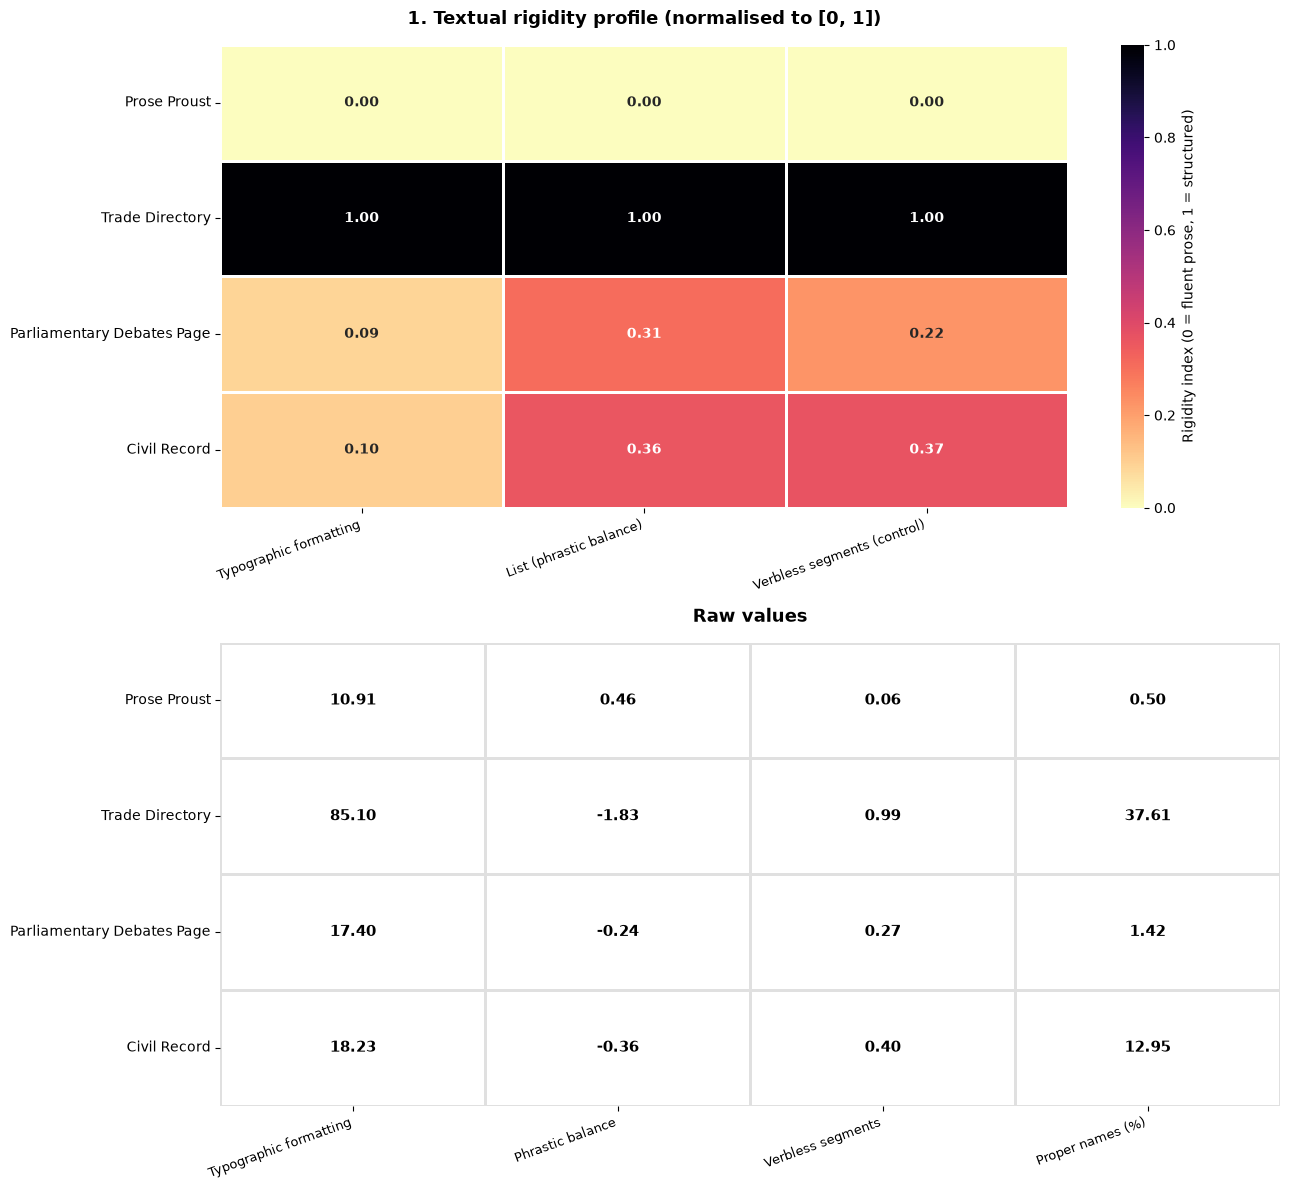

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

# 1. Calcul et Normalisation
results = []
for doc in corpus:
    m = get_all_metrics(doc["text"], lang=doc.get("lang", "fr"), ppl_models=PPL_MODELS)
    m["id"] = doc["id"]
    results.append(m)

df_res = pd.DataFrame(results)

def normalize(series: pd.Series, invert: bool = True) -> pd.Series:
    diff = series.max() - series.min()
    n = (series - series.min()) / (diff + 1e-5)
    return 1 - n if invert else n

# Nettoyage des noms de documents pour l'affichage
df_res["doc_label"] = (
    df_res["id"]
    .str.replace(r"^\d+_", "", regex=True)
    .str.replace("_", " ")
    .str.title()
)

df_final = pd.DataFrame({"Document": df_res["doc_label"]})

# Application des normalisations (indicateurs retenus de l'axe liste ↔ phrase ; la formularité demande
# une référence tirée d'un dataset et ne se calcule pas sur ces quatre documents isolés)
df_final["Typographic formatting"] = normalize(df_res["typo"], invert=False)
df_final["List (phrastic balance)"] = normalize(df_res["balance"], invert=True)
df_final["Verbless segments (control)"] = normalize(df_res["verbless"], invert=False)

# Création d'une figure avec 2 sous-graphiques empilés
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 12), dpi=100)

# GRAPHISME 1 : Carte Thermique des Valeurs Normalisées [0, 1]
sns.heatmap(
    df_final.set_index("Document"),
    annot=True,
    fmt=".2f",
    cmap="magma_r",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Rigidity index (0 = fluent prose, 1 = structured)"},
    annot_kws={"size": 10, "weight": "bold"},
    ax=ax1
)
ax1.set_title("1. Textual rigidity profile (normalised to [0, 1])", fontsize=13, pad=15, weight="bold")
ax1.set_xlabel("")
ax1.set_ylabel("")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=20, ha="right", fontsize=9)

# Préparation du DataFrame des valeurs brutes pour la table de texte / carte thermique annotée
df_raw = df_res.set_index("doc_label")[["typo", "balance", "verbless", "names"]].rename(columns={
    'typo': 'Typographic formatting',
    'balance': 'Phrastic balance',
    'verbless': 'Verbless segments',
    'names': 'Proper names (%)'
})

# GRAPHISME 2 : Carte d'affichage des Valeurs Brutes (sans couleur biaisée par les échelles différentes)
sns.heatmap(
    np.zeros_like(df_raw), # Matrice neutre (blanche) car les échelles brutes sont incomparables en couleur
    annot=df_raw,
    fmt=".2f",
    cmap="Greys",
    cbar=False, # Pas de barre de couleur car les échelles diffèrent
    linewidths=1,
    linecolor="#e0e0e0",
    annot_kws={"size": 11, "color": "black", "weight": "bold"},
    ax=ax2
)
ax2.set_title("Raw values", fontsize=13, pad=15, weight="bold")
ax2.set_xlabel("")
ax2.set_ylabel("")
ax2.set_xticklabels(df_raw.columns, rotation=20, ha="right", fontsize=9)
ax2.set_yticklabels(df_raw.index, rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

In [12]:
# Détail du formatage typographique par famille (marques pour 100 mots)
pd.DataFrame(
    [compute_typographic_formatting(d["text"]) for d in corpus],
    index=[d["id"] for d in corpus],
).round(1)

,typo_punctuation,typo_brackets,typo_separators,typo_symbols,typo_rules,typo_total,typo_no_punctuation
1_Prose_Proust,10.4,0.2,0.3,0.0,0.0,10.9,0.5
2_Trade_Directory,73.1,4.4,7.6,0.0,0.0,85.1,12.0
3_Parliamentary_Debates_Page,14.8,2.5,0.2,0.0,0.0,17.4,2.6
4_Civil_Record,15.8,2.0,0.0,0.5,0.0,18.2,2.5


In [13]:
# Vérification : les tokens SentencePiece sont-ils dans le vocabulaire du modèle KenLM ?
import unicodedata

from text_rigidity.perplexity import load_ccnet_model

test_text = "L'administration de la preuve dans l'acte d'avocat reste soumise."
sp, lm_ken = load_ccnet_model(SP_MODEL, LM_MODEL)

text_clean = unicodedata.normalize("NFKC", test_text.lower().strip())
tokens = sp.encode_as_pieces(text_clean)

print(f"{'SENTENCEPIECE TOKEN':<20} | {'KNOWN TO KENLM?':<20}")
print("-" * 45)
unrecognized = 0
for t in tokens:
    in_vocab = t in lm_ken
    if not in_vocab:
        unrecognized += 1
    print(f"{t:<20} | {'Yes' if in_vocab else 'NO (<unk>)'}")

print("-" * 45)
print(f"Recognition rate: {((len(tokens) - unrecognized) / len(tokens)) * 100:.1f}%")

SENTENCEPIECE TOKEN  | KNOWN TO KENLM?     
---------------------------------------------
▁l                   | Yes
'                    | Yes
ad                   | Yes
mini                 | Yes
stra                 | Yes
tion                 | Yes
▁de                  | Yes
▁la                  | Yes
▁preuve              | Yes
▁dans                | Yes
▁l                   | Yes
'                    | Yes
acte                 | Yes
▁d                   | Yes
'                    | Yes
avo                  | Yes
cat                  | Yes
▁reste               | Yes
▁soumise             | Yes
.                    | Yes
---------------------------------------------
Recognition rate: 100.0%


### III. Validation de ΔH à l'échelle corpus

ΔH dépend fortement de la taille de l'échantillon : on le calcule sur les N premiers mots de corpus publics de la table des datasets, pour N croissant. Corpus : annuaires SoDUCo (transcription de référence et OCR Pero, pour mesurer l'effet de l'OCR), presse HIPE-2022 (hipe2020-fr et letemps-fr, jeux de dev) et deux romans de 7romans. Téléchargement d'environ 12 Mo.

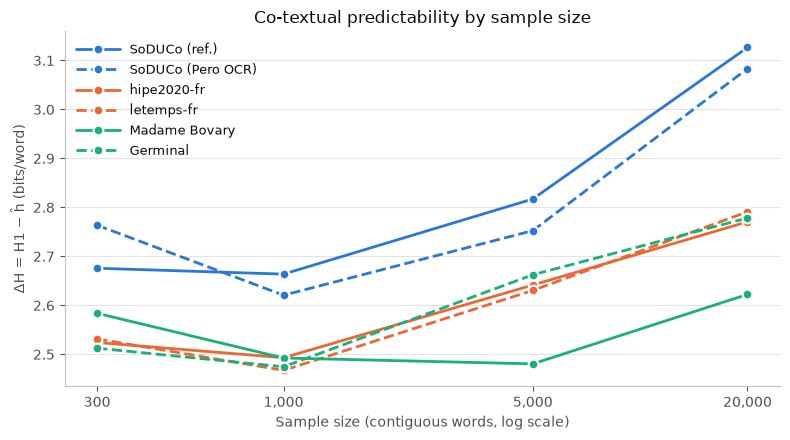

N,300,1000,5000,20000
corpus,,,,
Germinal,2.51,2.47,2.66,2.78
Madame Bovary,2.58,2.49,2.48,2.62
SoDUCo (Pero OCR),2.76,2.62,2.75,3.08
SoDUCo (ref.),2.68,2.66,2.82,3.13
hipe2020-fr,2.52,2.49,2.64,2.77
letemps-fr,2.53,2.47,2.63,2.79


In [14]:
import json
import re
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd


def _download(url: str) -> str:
    req = urllib.request.Request(url, headers={"User-Agent": "textual-rigidity-notebook/1.0"})
    with urllib.request.urlopen(req, timeout=120) as response:
        return response.read().decode("utf-8")


def hipe_tsv_to_text(tsv: str) -> str:
    """Reconstruit le texte d'un fichier HIPE-2022 (colonne TOKEN, espaces et sauts de ligne via MISC)."""
    out = []
    for line in tsv.splitlines():
        if not line or line.startswith(("#", "TOKEN\t")):
            continue
        parts = line.split("\t")
        out.append(parts[0])
        if "EndOfLine" in parts[-1]:
            out.append("\n")
        elif "NoSpaceAfter" not in parts[-1]:
            out.append(" ")
    return "".join(out)


def conll_to_text(conll: str) -> str:
    """Reconstruit le texte d'un roman de 7romans (un token par ligne, sans information d'espacement)."""
    text = " ".join(line.split(" ")[0] for line in conll.splitlines() if line.strip())
    text = re.sub(r" ([,.)\]])", r"\1", text)
    return re.sub(r"(\w) ' (\w)", r"\1'\2", text)


HIPE_URL = "https://raw.githubusercontent.com/hipe-eval/HIPE-2022-data/main/data/v2.1/{0}/fr/HIPE-2022-v2.1-{0}-dev-fr.tsv"
ROMANS_URL = "https://raw.githubusercontent.com/obtic-sorbonne/7-romans/main/ner/{}.conll"
SODUCO_URL = "https://zenodo.org/records/8167628/files/dataset_SODUCO_nested_ner.json?download=1"

soduco = sorted(json.loads(_download(SODUCO_URL)), key=lambda e: (e["book"], e["page"], e["id"]))

# (famille, nom, texte) : la famille fixe la couleur, la variante le style de trait
validation_corpora = [
    ("Directories", "SoDUCo (ref.)", "\n".join(e["text_ocr_ref"] for e in soduco)),
    ("Directories", "SoDUCo (Pero OCR)", "\n".join(e["text_ocr_pero"] for e in soduco)),
    ("Press", "hipe2020-fr", hipe_tsv_to_text(_download(HIPE_URL.format("hipe2020")))),
    ("Press", "letemps-fr", hipe_tsv_to_text(_download(HIPE_URL.format("letemps")))),
    ("Novels", "Madame Bovary", conll_to_text(_download(ROMANS_URL.format("MadameBovary")))),
    ("Novels", "Germinal", conll_to_text(_download(ROMANS_URL.format("Germinal")))),
]

rows = []
for family, name, text in validation_corpora:
    tokens = tokenize_words(text)
    for n in [300, 1000, 5000, DELTA_H_TOKENS]:
        if len(tokens) >= n:
            sample = tokens[:n]
            rows.append({
                "family": family,
                "corpus": name,
                "N": n,
                "delta_H": unigram_entropy(sample) - entropy_rate_lz(sample),
            })
df_dh = pd.DataFrame(rows)

FAMILY_COLORS = {"Directories": "#2a78d6", "Press": "#eb6834", "Novels": "#1baf7a"}
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=100)
seen = {}
for (family, name), g in df_dh.groupby(["family", "corpus"], sort=False):
    linestyle = "-" if family not in seen else "--"
    seen[family] = True
    ax.plot(
        g["N"], g["delta_H"], color=FAMILY_COLORS[family], linestyle=linestyle, linewidth=2,
        marker="o", markersize=7, markeredgecolor="white", markeredgewidth=1.5,
        solid_capstyle="round", label=name,
    )
ax.set_xscale("log")
ax.set_xticks([300, 1000, 5000, DELTA_H_TOKENS], labels=["300", "1,000", "5,000", f"{DELTA_H_TOKENS:,}"])
ax.minorticks_off()
ax.set_xlabel("Sample size (contiguous words, log scale)", color="#52514e")
ax.set_ylabel("ΔH = H1 − ĥ (bits/word)", color="#52514e")
ax.set_title("Co-textual predictability by sample size", color="#0b0b0b")
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.legend(frameon=False, fontsize=9, labelcolor="#0b0b0b", handlelength=3.5)
plt.tight_layout()
plt.show()

df_dh.pivot(index="corpus", columns="N", values="delta_H").round(2)

### IV. Relance sur les datasets du projet

Les indicateurs retenus ont été recalculés sur les datasets de la table (33 sous-corpus, fenêtres de 100 et de 300 mots, 100 fenêtres au plus par sous-corpus, tirées à tour de rôle dans les documents). Les scripts sont dans `dataset-validation/` :
- `loaders.py` lit les datasets bruts de `data/` (racine du dépôt) et les convertit dans un format commun (texte et spans d'entités) ;
- `compute_indicators.py` tire les fenêtres et calcule les indicateurs avec le package `text_rigidity` ;
- `analysis.py` produit les profils par dataset, les corrélations, les mesures de fiabilité et la validation de la densité de noms propres ;
- `figure.py` trace la figure des deux axes.

Les résultats sont dans `dataset-validation/results/`, et leur lecture dans [`indicateurs-rigidite.md`](indicateurs-rigidite.md).